In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Metro_Traffic.csv")

In [5]:
df["holiday"] = df["holiday"].fillna("None")

In [7]:
num_cols = df.select_dtypes(include = np.number).columns

In [8]:
for cols in num_cols:
    df[cols] = df[cols].fillna(df[cols].median())

In [9]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64


In [10]:
print("Duplicates Rows: ",df.duplicated().sum())
print("Duplicates Rows in percentage: ",df.duplicated().mean() * 100)

Duplicates Rows:  17
Duplicates Rows in percentage:  0.03526678283959837


In [11]:
df = df.drop_duplicates().copy()

In [12]:
df.shape

(48187, 9)

In [13]:
df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month

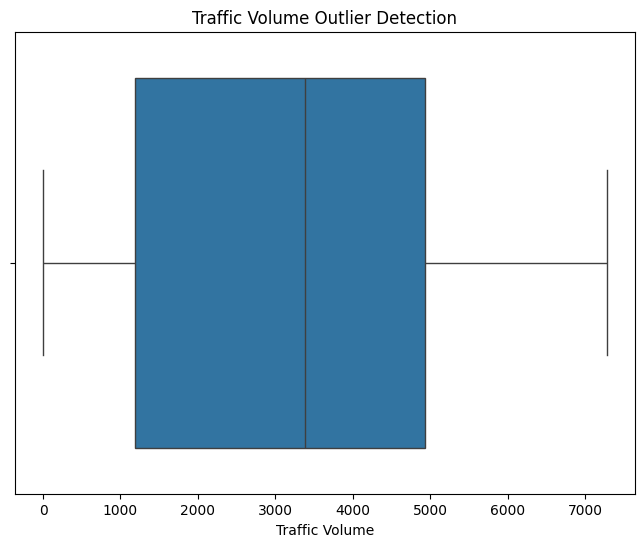

In [14]:
plt.figure(figsize= (8,6))

sns.boxplot(x = df["traffic_volume"])
plt.title("Traffic Volume Outlier Detection")
plt.xlabel("Traffic Volume")

plt.show()

calculate the interquartile range (IQR):

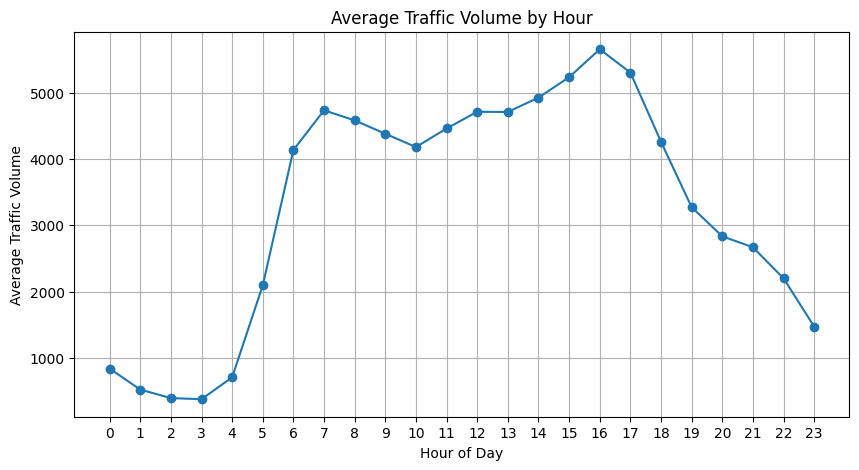

In [17]:
hourly_traffic = df.groupby("hour")["traffic_volume"].mean()

plt.figure(figsize=(10, 5))

plt.plot(hourly_traffic.index,
         hourly_traffic.values,
         marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.title("Average Traffic Volume by Hour")
plt.xticks(range(24))
plt.grid(True)

plt.show()

Compare weekdays and weekends

In [18]:
df["is_weekend"] = df["day_of_week"].isin([5, 6])

weekend_traffic = df.groupby("is_weekend")["traffic_volume"].mean()

print(weekend_traffic)

is_weekend
False    3533.291791
True     2570.699635
Name: traffic_volume, dtype: float64


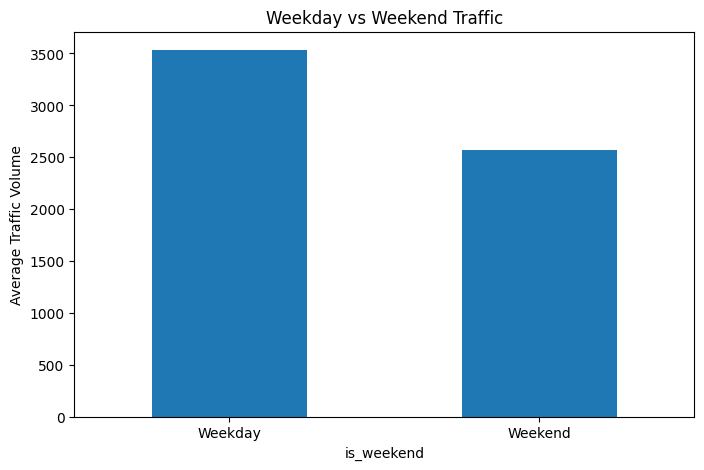

In [20]:
weekend_traffic.plot(kind = "bar", figsize=(8,5))
plt.xticks([0, 1], ["Weekday", "Weekend"], rotation=0)
plt.ylabel("Average Traffic Volume")
plt.title("Weekday vs Weekend Traffic")
plt.show()

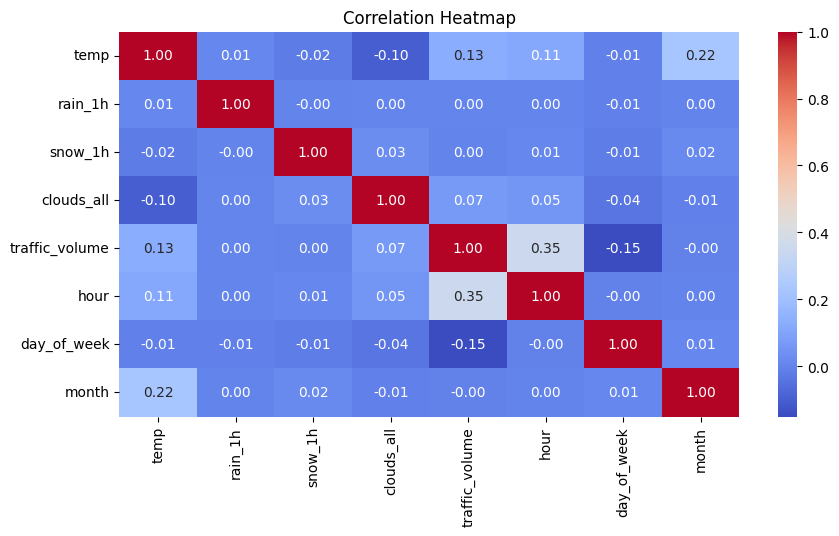

In [27]:
numeric_df = df.select_dtypes(include = np.number)

corr = numeric_df.corr()

plt.figure(figsize=(10,5))

sns.heatmap(corr, 
           annot = True,
           cmap="coolwarm",
           fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

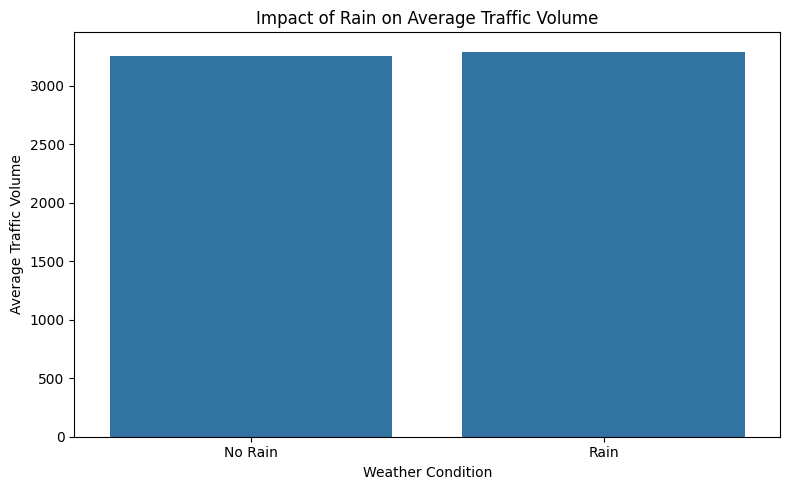

In [30]:
# Create rain categories
df['rain_condition'] = df['rain_1h'].apply(
    lambda x: 'Rain' if x > 0 else 'No Rain'
)

# Calculate average traffic volume
rain_traffic = df.groupby(
    'rain_condition'
)['traffic_volume'].mean().reset_index()

# Plot bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    data=rain_traffic,
    x='rain_condition',
    y='traffic_volume'
)

plt.title('Impact of Rain on Average Traffic Volume')
plt.xlabel('Weather Condition')
plt.ylabel('Average Traffic Volume')
plt.tight_layout()
plt.show()

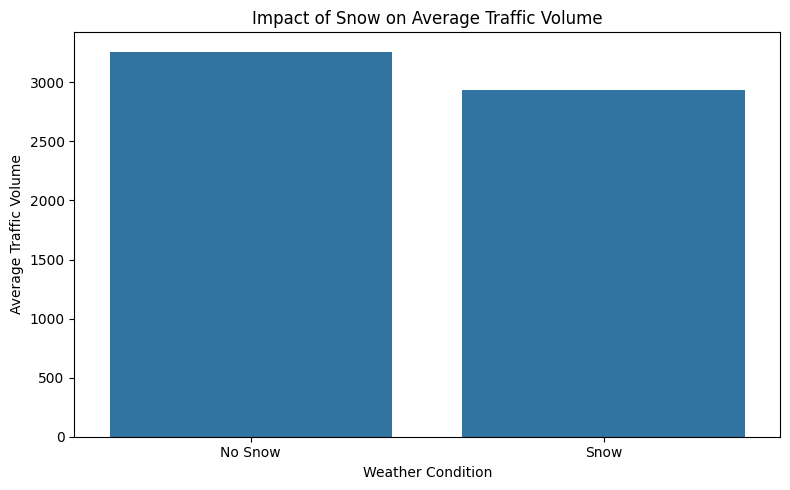

In [31]:
df['snow_condition'] = df['snow_1h'].apply(
    lambda x: 'Snow' if x > 0 else 'No Snow'
)

snow_traffic = df.groupby(
    'snow_condition'
)['traffic_volume'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=snow_traffic,
    x='snow_condition',
    y='traffic_volume'
)

plt.title('Impact of Snow on Average Traffic Volume')
plt.xlabel('Weather Condition')
plt.ylabel('Average Traffic Volume')
plt.tight_layout()
plt.show()

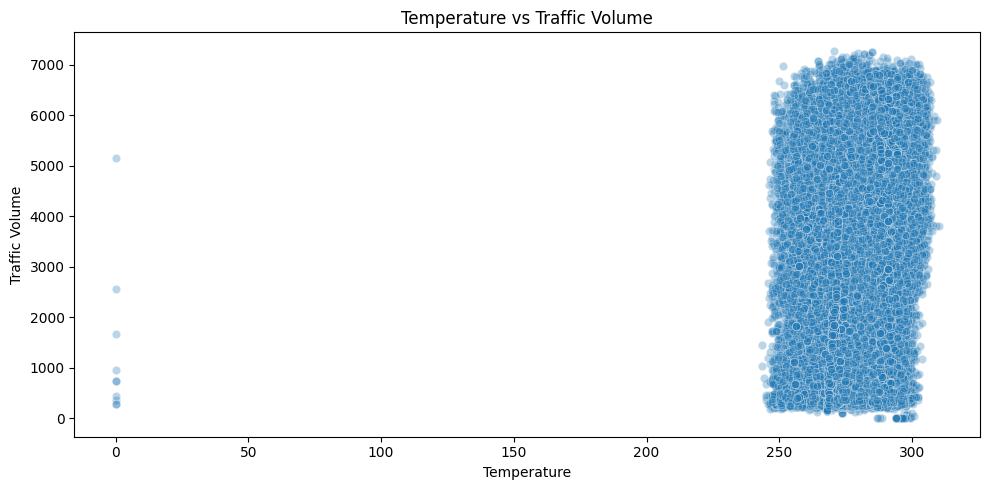

In [32]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='temp',
    y='traffic_volume',
    alpha=0.3
)

plt.title('Temperature vs Traffic Volume')
plt.xlabel('Temperature')
plt.ylabel('Traffic Volume')
plt.tight_layout()
plt.show()

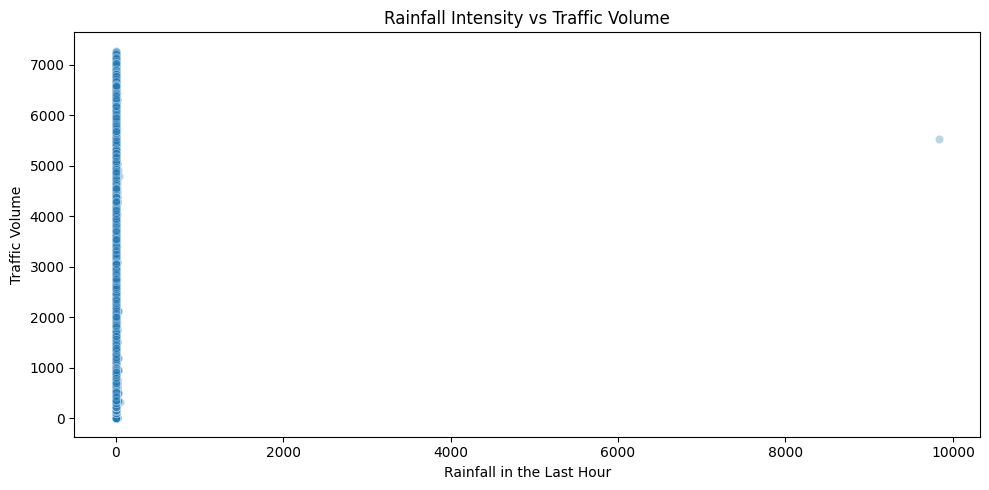

In [33]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='rain_1h',
    y='traffic_volume',
    alpha=0.3
)

plt.title('Rainfall Intensity vs Traffic Volume')
plt.xlabel('Rainfall in the Last Hour')
plt.ylabel('Traffic Volume')
plt.tight_layout()
plt.show()